<a href="https://colab.research.google.com/github/Akash-hasnat/Sleep-disorder/blob/main/Sleep_Disorder_XAI_Colab(main).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sleep Disorder Classification — Advanced Ensemble + Multi-XAI (SHAP/LIME/ELI5)
**For conference submission.**

Pipeline:
1. Load data (upload `Sleep_Data_Sampled.csv`)
2. EDA + duplicate/leakage check
3. Feature engineering
4. **Leak-free train/test split** (novelty piece #1 — most public notebooks on this dataset leak duplicates across train/test)
5. Stacked ensemble: XGBoost + LightGBM + CatBoost → Logistic Regression meta-learner
6. Naive vs leak-free comparison table (quantifies the leakage effect)
7. SHAP, LIME, ELI5 explainability
8. **Cross-XAI Agreement Analysis** (novelty piece #2 — Kendall's Tau rank correlation between the three explanation methods)


In [ ]:
# ===== 1. Install dependencies (Colab-safe) =====
!pip install -q xgboost lightgbm catboost shap lime eli5 scikit-learn seaborn matplotlib


In [ ]:
# ===== 2. Upload the dataset =====
# Run this cell, then choose Sleep_Data_Sampled.csv from your computer.
from google.colab import files
import io, os

if not os.path.exists('/content/drive/MyDrive/paper/Insomnia /Sleep_Data_Sampled.csv'):
    uploaded = files.upload()
    fname = list(uploaded.keys())[0]
    os.rename(fname, '/content/drive/MyDrive/paper/Insomnia /Sleep_Data_Sampled.csv')

DATA_PATH = '/content/drive/MyDrive/paper/Insomnia /Sleep_Data_Sampled.csv'
OUT_DIR = '/content/outputs'
os.makedirs(OUT_DIR, exist_ok=True)
print('Data ready at', DATA_PATH)


Data ready at /content/drive/MyDrive/paper/Insomnia /Sleep_Data_Sampled.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ===== 3. Imports =====
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import StackingClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

import shap
from lime.lime_tabular import LimeTabularExplainer
import eli5
from eli5.sklearn import PermutationImportance
from scipy.stats import kendalltau

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


In [ ]:
# Define preprocessing functions and constants for the stacking model (adapted from other cells)

# Assuming DATA_PATH is already defined in an earlier cell (e.g., b2ffd62f)
# from google.colab import drive
# drive.mount('/content/drive')
# DATA_PATH = '/content/drive/MyDrive/paper/Insomnia /Sleep_Data_Sampled.csv'

# Constants
TARGET_COL = 'Sleep Disorder'
CLASS_NAMES = ['Healthy', 'Insomnia', 'Sleep Apnea'] # inferred from cell 8975d19c

# Feature Engineering (from cell 8975d19c)
def engineer_features(df):
    df = df.copy()
    bp = df['Blood Pressure'].str.split('/', expand=True)
    df['Systolic_BP'] = bp[0].astype(int)
    df['Diastolic_BP'] = bp[1].astype(int)
    df = df.drop(columns=['Blood Pressure'])

    df['BMI Category'] = df['BMI Category'].replace({'Normal Weight': 'Normal'})
    df = df.drop(columns=['Person ID'])

    df['Steps_per_ActivityLevel'] = df['Daily Steps'] / df['Physical Activity Level'].replace(0, 1)
    df['Stress_to_Sleep_ratio'] = df['Stress Level'] / df['Sleep Duration']
    df['Pulse_pressure'] = df['Systolic_BP'] - df['Diastolic_BP']
    return df

# Encoding (adapted from cell 8975d19c for train/test split)
def encode_categoricals_fit_on_train(train_df, test_df):
    train_df = train_df.copy()
    test_df = test_df.copy()

    cat_cols = [c for c in train_df.select_dtypes(include='object').columns if c != TARGET_COL]

    for c in cat_cols:
        le = LabelEncoder()
        train_df[c] = le.fit_transform(train_df[c])
        test_df[c] = le.transform(test_df[c]) # Transform test using encoder fitted on train

    # Encode target column as well, if it's object type (though it should be handled numerically later)
    if train_df[TARGET_COL].dtype == 'object':
        target_le = LabelEncoder()
        train_df[TARGET_COL] = target_le.fit_transform(train_df[TARGET_COL])
        test_df[TARGET_COL] = target_le.transform(test_df[TARGET_COL])

    return train_df, test_df

# Load and engineer function (adapted from load_data in cell 24d8rdzELdqw and engineer_features/encode)
def load_and_engineer(csv_path: str) -> pd.DataFrame:
    df_raw = pd.read_csv(csv_path)
    df_feat = engineer_features(df_raw)

    # Re-derive feature columns after engineering
    global FEATURE_COLS
    FEATURE_COLS = [c for c in df_feat.columns if c not in [TARGET_COL, 'Person ID']]

    return df_feat


# Initial FEATURE_COLS (will be updated by load_and_engineer)
FEATURE_COLS = [
    "Gender", "Age", "Occupation", "Sleep Duration", "Quality of Sleep",
    "Physical Activity Level", "Stress Level", "BMI Category", "Heart Rate",
    "Daily Steps", "Systolic_BP", "Diastolic_BP", "Steps_per_ActivityLevel",
    "Stress_to_Sleep_ratio", "Pulse_pressure"
]

print("Preprocessing functions and constants are now defined.")

Preprocessing functions and constants are now defined.


### Custom `NumpyAttentionMetaLearner` Class Definition

This class implements a simple attention-based meta-learner using NumPy. It takes the output probabilities from multiple base models and learns dynamic 'attention' weights for each base model's contribution to the final prediction. This mechanism helps the meta-learner to focus on more reliable base models for specific predictions.

In [ ]:
import numpy as np

class NumpyAttentionMetaLearner:
    def __init__(self, n_models, n_classes, hidden, lr, l2):
        self.n_models = n_models
        self.n_classes = n_classes
        self.hidden = hidden # This 'hidden' is for the attention network's hidden layer
        self.lr = lr
        self.l2 = l2

        # Weights for the attention mechanism
        # The input to the attention network for each sample is the flattened probabilities
        # from all base models: (n_models * n_classes).
        self.W_attn_h = np.random.randn(n_models * n_classes, self.hidden) * 0.01
        self.b_attn_h = np.zeros(self.hidden)

        # Output layer of the attention network: produces unnormalized attention scores for each model
        self.W_attn_out = np.random.randn(self.hidden, n_models) * 0.01
        self.b_attn_out = np.zeros(n_models)

    def _softmax(self, x):
        # Stable softmax calculation
        exp_x = np.exp(x - np.max(x, axis=-1, keepdims=True))
        return exp_x / np.sum(exp_x, axis=-1, keepdims=True)

    def _forward(self, P):
        # P: (N, n_models, n_classes) - stacked probabilities from base models
        N = P.shape[0]
        P_flat = P.reshape(N, -1) # Flatten probabilities: (N, n_models * n_classes)

        # Attention Network Forward Pass
        # Hidden layer with ReLU activation
        attn_h_pre_relu = P_flat @ self.W_attn_h + self.b_attn_h
        attn_h = np.maximum(0, attn_h_pre_relu) # (N, hidden)

        # Output attention scores, then softmax to get weights
        attn_scores = attn_h @ self.W_attn_out + self.b_attn_out # (N, n_models)
        attn_weights = self._softmax(attn_scores) # (N, n_models), sum to 1 across models for each sample

        # Apply attention weights to base model probabilities
        # Expand attn_weights to (N, n_models, 1) for broadcasting
        weighted_P = attn_weights[:, :, None] * P # (N, n_models, n_classes)
        final_probs = np.sum(weighted_P, axis=1) # Sum across models: (N, n_classes) - final predictions

        return final_probs, attn_weights, attn_h, attn_h_pre_relu

    def fit(self, P_oof, y_oof, epochs):
        N = P_oof.shape[0]
        # One-hot encode true labels for cross-entropy loss
        y_onehot = np.zeros((N, self.n_classes))
        y_onehot[np.arange(N), y_oof] = 1

        for epoch in range(epochs):
            # Forward pass
            final_probs, attn_weights, attn_h, attn_h_pre_relu = self._forward(P_oof)

            # Compute loss (cross-entropy + L2 regularization)
            loss = -np.sum(y_onehot * np.log(final_probs + 1e-9)) / N
            loss += 0.5 * self.l2 * (np.sum(self.W_attn_h**2) + np.sum(self.W_attn_out**2))

            if epoch % 100 == 0 or epoch == epochs - 1:
                print(f"Epoch {epoch}, Loss: {loss:.4f}")

            # Backward pass (gradients using chain rule)
            d_final_probs = (final_probs - y_onehot) / N # Gradient of cross-entropy w.r.t. final_probs

            # Gradient back to weighted_P. Reshape for broadcasting.
            d_weighted_P = d_final_probs[:, None, :] # (N, 1, n_classes)

            # Gradient w.r.t. attn_weights and P
            d_attn_weights = np.sum(d_weighted_P * P_oof, axis=2) # (N, n_models)

            # Gradient w.r.t. attn_scores (from softmax)
            # This is the Jacobian of softmax: S_ij * (delta_ij - S_j). Simplified form for cross-entropy.
            d_attn_scores = attn_weights * (d_attn_weights - np.sum(d_attn_weights * attn_weights, axis=1, keepdims=True)) # (N, n_models)

            # Gradients for W_attn_out and b_attn_out
            dW_attn_out = attn_h.T @ d_attn_scores + self.l2 * self.W_attn_out
            db_attn_out = np.sum(d_attn_scores, axis=0)

            # Gradient back through ReLU hidden layer
            d_attn_h = d_attn_scores @ self.W_attn_out.T # (N, hidden)
            # Only pass gradient for units where pre-activation was > 0
            d_attn_h[attn_h_pre_relu <= 0] = 0

            # Gradients for W_attn_h and b_attn_h
            P_oof_flat = P_oof.reshape(N, -1)
            dW_attn_h = P_oof_flat.T @ d_attn_h + self.l2 * self.W_attn_h
            db_attn_h = np.sum(d_attn_h, axis=0)

            # Update weights
            self.W_attn_h -= self.lr * dW_attn_h
            self.b_attn_h -= self.lr * db_attn_h
            self.W_attn_out -= self.lr * dW_attn_out
            self.b_attn_out -= self.lr * db_attn_out

    def predict(self, P_test):
        final_probs, attn_weights_test, _, _ = self._forward(P_test)
        y_pred = np.argmax(final_probs, axis=1)
        return y_pred, final_probs, attn_weights_test

## Step 1 — Load & inspect (duplicate / leakage check)

In [ ]:
df_raw = pd.read_csv(DATA_PATH)
print('Shape:', df_raw.shape)
print(df_raw.head())

print('\nMissing values:\n', df_raw.isnull().sum())

dup_check = df_raw.drop(columns=['Person ID']).duplicated().sum()
unique_rows = df_raw.drop(columns=['Person ID']).drop_duplicates().shape[0]
print(f'\nDuplicate rows (excl. Person ID): {dup_check}')
print(f'Unique rows: {unique_rows} out of {df_raw.shape[0]}')
print(f'-> {dup_check/df_raw.shape[0]*100:.1f}% of rows are duplicates.')
print('This 94     reply94     reply     replyis why we need a LEAK-FREE split (see Step 3).')

print('\nTarget distribution:\n', df_raw['Sleep Disorder'].value_counts())


Shape: (15000, 13)
   Person ID Gender  Age         Occupation  Sleep Duration  Quality of Sleep  \
0          1   Male   35             Doctor            6.65                 7   
1          2   Male   42            Teacher            6.90                 8   
2          3   Male   34  Software Engineer            6.95                 7   
3          4   Male   32             Doctor            6.90                 6   
4          5   Male   37             Lawyer            6.85                 7   

   Physical Activity Level  Stress Level   BMI Category Blood Pressure  \
0                       50             7  Normal Weight         120/80   
1                       52             4         Normal         135/90   
2                       66             6     Overweight         126/83   
3                       52             7         Normal         120/80   
4                       60             6         Normal         125/80   

   Heart Rate  Daily Steps Sleep Disorder  
0    

## Step 2 — Feature engineering

In [ ]:
def engineer_features(df):
    df = df.copy()
    bp = df['Blood Pressure'].str.split('/', expand=True)
    df['Systolic_BP'] = bp[0].astype(int)
    df['Diastolic_BP'] = bp[1].astype(int)
    df = df.drop(columns=['Blood Pressure'])

    df['BMI Category'] = df['BMI Category'].replace({'Normal Weight': 'Normal'})
    df = df.drop(columns=['Person ID'])

    df['Steps_per_ActivityLevel'] = df['Daily Steps'] / df['Physical Activity Level'].replace(0, 1)
    df['Stress_to_Sleep_ratio'] = df['Stress Level'] / df['Sleep Duration']
    df['Pulse_pressure'] = df['Systolic_BP'] - df['Diastolic_BP']
    return df

def encode(df, target_col='Sleep Disorder'):
    df = df.copy()
    cat_cols = [c for c in df.select_dtypes(include='object').columns if c != target_col]
    encoders = {}
    for c in cat_cols:
        le = LabelEncoder()
        df[c] = le.fit_transform(df[c])
        encoders[c] = le
    target_le = LabelEncoder()
    df[target_col] = target_le.fit_transform(df[target_col])
    encoders['__target__'] = target_le
    return df, encoders

df_feat = engineer_features(df_raw)
df_enc, encoders = encode(df_feat)
label_names = list(encoders['__target__'].classes_)
target_col = 'Sleep Disorder'
feature_cols = [c for c in df_enc.columns if c != target_col]
print('Features:', feature_cols)
print('Classes:', label_names)
df_enc.head()


Features: ['Gender', 'Age', 'Occupation', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'BMI Category', 'Heart Rate', 'Daily Steps', 'Systolic_BP', 'Diastolic_BP', 'Steps_per_ActivityLevel', 'Stress_to_Sleep_ratio', 'Pulse_pressure']
Classes: ['Healthy', 'Insomnia', 'Sleep Apnea']


,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic_BP,Diastolic_BP,Steps_per_ActivityLevel,Stress_to_Sleep_ratio,Pulse_pressure
0,1,35,1,6.65,7,50,7,0,71,7100,0,120,80,142.000000,1.052632,40
1,1,42,10,6.90,8,52,4,0,66,7000,0,135,90,134.615385,0.579710,45
2,1,34,9,6.95,7,66,6,2,74,6100,0,126,83,92.424242,0.863309,43
3,1,32,1,6.90,6,52,7,0,71,6500,0,120,80,125.000000,1.014493,40
4,1,37,3,6.85,7,60,6,0,71,6500,0,125,80,108.333333,0.875912,45


## Step 3 — Leak-free train/test split (Novelty #1)

We deduplicate first, split the **unique** rows, then expand the train side
back to its duplicates (for more training signal) while keeping the test
set strictly unique and disjoint from train. We also build a **naive split**
(splitting the raw duplicated data directly) purely to demonstrate the
leakage effect afterwards.

In [ ]:
def leak_free_split(df_encoded, target_col, test_size=0.2):
    feature_cols = [c for c in df_encoded.columns if c != target_col]
    unique_df = df_encoded.drop_duplicates(subset=feature_cols + [target_col]).reset_index(drop=True)

    train_unique, test_unique = train_test_split(
        unique_df, test_size=test_size, stratify=unique_df[target_col],
        random_state=RANDOM_STATE
    )

    merge_keys = feature_cols + [target_col]
    train_full = df_encoded.merge(train_unique[merge_keys], on=merge_keys, how='inner')

    test_keys = set(map(tuple, test_unique[merge_keys].values))
    train_keys = set(map(tuple, train_full[merge_keys].values))
    overlap = test_keys & train_keys
    assert len(overlap) == 0, f'Leakage detected! {len(overlap)} overlapping rows'

    naive_train, naive_test = train_test_split(
        df_encoded, test_size=test_size, stratify=df_encoded[target_col],
        random_state=RANDOM_STATE
    )

    return train_full, test_unique, naive_train, naive_test

train_full, test_unique, naive_train, naive_test = leak_free_split(df_enc, target_col)

print('Leak-free train (with dup expansion):', train_full.shape)
print('Leak-free test (strictly unique)     :', test_unique.shape)
print('Naive train                          :', naive_train.shape)
print('Naive test                           :', naive_test.shape)

def get_xy(df):
    return df[feature_cols].values, df[target_col].values

X_train, y_train = get_xy(train_full)
X_test, y_test = get_xy(test_unique)
Xn_train, yn_train = get_xy(naive_train)
Xn_test, yn_test = get_xy(naive_test)


Leak-free train (with dup expansion): (12005, 16)
Leak-free test (strictly unique)     : (960, 16)
Naive train                          : (12000, 16)
Naive test                           : (3000, 16)


## Step 4 — Models: baseline + advanced stacked ensemble


=== Baseline_LogReg_LeakFree ===
Accuracy: 0.7948  Macro-F1: 0.7795
              precision    recall  f1-score   support

     Healthy       0.86      0.82      0.84       486
    Insomnia       0.72      0.75      0.74       239
 Sleep Apnea       0.74      0.78      0.76       235

    accuracy                           0.79       960
   macro avg       0.77      0.78      0.78       960
weighted avg       0.80      0.79      0.80       960



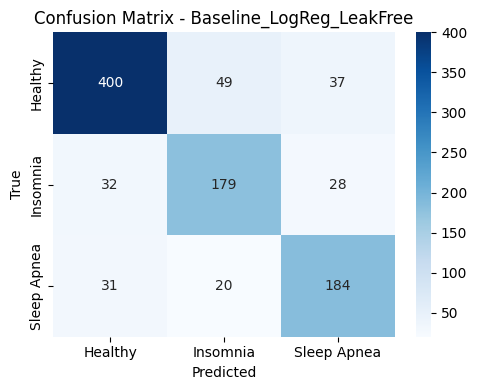


=== StackedEnsemble_LeakFree ===
Accuracy: 0.9052  Macro-F1: 0.8963
              precision    recall  f1-score   support

     Healthy       0.95      0.91      0.93       486
    Insomnia       0.85      0.91      0.88       239
 Sleep Apnea       0.87      0.88      0.88       235

    accuracy                           0.91       960
   macro avg       0.89      0.90      0.90       960
weighted avg       0.91      0.91      0.91       960



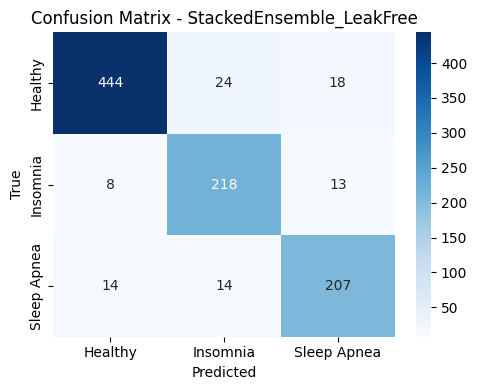


=== StackedEnsemble_NAIVE_leaky ===
Accuracy: 0.9740  Macro-F1: 0.9740
              precision    recall  f1-score   support

     Healthy       0.97      0.96      0.97      1000
    Insomnia       0.97      0.98      0.98      1000
 Sleep Apnea       0.97      0.98      0.98      1000

    accuracy                           0.97      3000
   macro avg       0.97      0.97      0.97      3000
weighted avg       0.97      0.97      0.97      3000



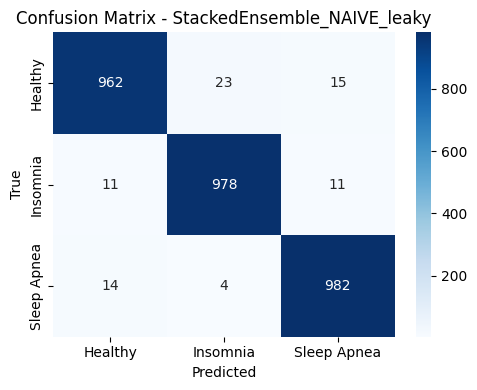


=== Leakage effect summary ===
                        tag  accuracy  macro_f1
   Baseline_LogReg_LeakFree  0.794792  0.779479
   StackedEnsemble_LeakFree  0.905208  0.896282
StackedEnsemble_NAIVE_leaky  0.974000  0.973981


In [ ]:
def build_stack():
    xgb_clf = xgb.XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                                 subsample=0.8, colsample_bytree=0.8,
                                 random_state=RANDOM_STATE, eval_metric='mlogloss')
    lgb_clf = lgb.LGBMClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                                  subsample=0.8, colsample_bytree=0.8,
                                  random_state=RANDOM_STATE, verbose=-1)
    cat_clf = CatBoostClassifier(iterations=300, depth=5, learning_rate=0.05,
                                  random_state=RANDOM_STATE, verbose=0)
    stack = StackingClassifier(
        estimators=[('xgb', xgb_clf), ('lgb', lgb_clf), ('cat', cat_clf)],
        final_estimator=LogisticRegression(max_iter=1000),
        cv=5, n_jobs=-1
    )
    return stack

def evaluate(model, X_test, y_test, tag, plot=True):
    preds = model.predict(X_test)
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, average='macro')
    print(f'\n=== {tag} ===')
    print(f'Accuracy: {acc:.4f}  Macro-F1: {f1:.4f}')
    print(classification_report(y_test, preds, target_names=label_names))
    if plot:
        cm = confusion_matrix(y_test, preds)
        plt.figure(figsize=(5, 4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=label_names, yticklabels=label_names)
        plt.title(f'Confusion Matrix - {tag}')
        plt.ylabel('True'); plt.xlabel('Predicted')
        plt.tight_layout()
        plt.savefig(f'{OUT_DIR}/confusion_matrix_{tag.replace(" ", "_")}.png', dpi=150)
        plt.show()
    return {'tag': tag, 'accuracy': acc, 'macro_f1': f1}

results = []

# Baseline
scaler = StandardScaler()
Xtr_s = scaler.fit_transform(X_train)
Xte_s = scaler.transform(X_test)
baseline = LogisticRegression(max_iter=1000)
baseline.fit(Xtr_s, y_train)
results.append(evaluate(baseline, Xte_s, y_test, 'Baseline_LogReg_LeakFree'))

# Advanced stacked ensemble - leak-free (the real evaluation)
stack = build_stack()
stack.fit(X_train, y_train)
results.append(evaluate(stack, X_test, y_test, 'StackedEnsemble_LeakFree'))

# Same model on the NAIVE split (to show the leakage inflation)
stack_naive = build_stack()
stack_naive.fit(Xn_train, yn_train)
results.append(evaluate(stack_naive, Xn_test, yn_test, 'StackedEnsemble_NAIVE_leaky'))

res_df = pd.DataFrame(results)
res_df.to_csv(f'{OUT_DIR}/model_comparison.csv', index=False)
print('\n=== Leakage effect summary ===')
print(res_df.to_string(index=False))


## Step 4b — Extended Model Comparison (12 models, for the paper's results table)

Trains many models on the SAME leak-free split so you can show a full
comparison table + charts in the paper: Logistic Regression, KNN, SVM,
Decision Tree, Random Forest, Gradient Boosting, XGBoost, LightGBM,
CatBoost, Voting (soft), Stacking (your main proposed model), and an
MLP neural network. Includes Accuracy, Macro-F1, Precision, Recall,
ROC-AUC, and 5-fold CV accuracy (skipped for Voting/Stacking to avoid
extremely expensive nested-CV refits).

Note: SVM is trained on a 3,000-row stratified subsample (RBF-kernel SVM
does not scale to 12k rows in reasonable time) — this is noted in the
model name in the results table.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import label_binarize
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.metrics import precision_score, recall_score, roc_auc_score

scaler2 = StandardScaler()
X_train_s = scaler2.fit_transform(X_train)
X_test_s = scaler2.transform(X_test)

SVM_MAX_N = 3000
X_train_svm, _, y_train_svm, _ = train_test_split(
    X_train_s, y_train, train_size=SVM_MAX_N, stratify=y_train, random_state=RANDOM_STATE
)

voting = VotingClassifier(
    estimators=[
        ('xgb', xgb.XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                                   subsample=0.8, colsample_bytree=0.8,
                                   random_state=RANDOM_STATE, eval_metric='mlogloss')),
        ('lgb', lgb.LGBMClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                                    subsample=0.8, colsample_bytree=0.8,
                                    random_state=RANDOM_STATE, verbose=-1)),
        ('cat', CatBoostClassifier(iterations=300, depth=5, learning_rate=0.05,
                                    random_state=RANDOM_STATE, verbose=0)),
    ], voting='soft'
)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(n_neighbors=7),
    'SVM (RBF)': SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=8, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, max_depth=4, random_state=RANDOM_STATE),
    'XGBoost': xgb.XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                                  subsample=0.8, colsample_bytree=0.8,
                                  random_state=RANDOM_STATE, eval_metric='mlogloss'),
    'LightGBM': lgb.LGBMClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                                    subsample=0.8, colsample_bytree=0.8,
                                    random_state=RANDOM_STATE, verbose=-1),
    'CatBoost': CatBoostClassifier(iterations=300, depth=5, learning_rate=0.05,
                                    random_state=RANDOM_STATE, verbose=0),
    'Voting (XGB+LGB+CAT)': voting,
    'Stacking (XGB+LGB+CAT+LR)': stack,   # reuse the already-trained stack from Step 4
    'MLP Neural Network': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=RANDOM_STATE),
}

NEEDS_SCALING = {'Logistic Regression', 'KNN', 'SVM (RBF)', 'MLP Neural Network'}
SKIP_OUTER_CV = {'Stacking (XGB+LGB+CAT+LR)', 'Voting (XGB+LGB+CAT)'}
n_classes = len(label_names)

def evaluate_model(name, model, Xtr, ytr, Xte, yte, skip_cv=False):
    preds = model.predict(Xte)
    proba = model.predict_proba(Xte) if hasattr(model, 'predict_proba') else None
    acc = accuracy_score(yte, preds)
    f1 = f1_score(yte, preds, average='macro')
    prec = precision_score(yte, preds, average='macro', zero_division=0)
    rec = recall_score(yte, preds, average='macro', zero_division=0)
    if proba is not None:
        yte_bin = label_binarize(yte, classes=list(range(n_classes)))
        try:
            auc = roc_auc_score(yte_bin, proba, average='macro', multi_class='ovr')
        except ValueError:
            auc = np.nan
    else:
        auc = np.nan
    if skip_cv:
        cvm, cvs = np.nan, np.nan
    else:
        cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
        cvsc = cross_val_score(model, Xtr, ytr, cv=cv, scoring='accuracy', n_jobs=-1)
        cvm, cvs = cvsc.mean(), cvsc.std()
    return {'Model': name, 'Test Accuracy': acc, 'Macro F1': f1, 'Macro Precision': prec,
            'Macro Recall': rec, 'ROC-AUC (OVR)': auc, 'CV Accuracy (mean)': cvm, 'CV Accuracy (std)': cvs}

rows = []
for name, model in models.items():
    print(f'Training {name} ...')
    skip_cv = name in SKIP_OUTER_CV
    if name == 'SVM (RBF)':
        model.fit(X_train_svm, y_train_svm)
        row = evaluate_model(name, model, X_train_svm, y_train_svm, X_test_s, y_test, skip_cv)
        row['Model'] = name + f' [trained on {SVM_MAX_N} subsample]'
    elif name in NEEDS_SCALING:
        model.fit(X_train_s, y_train)
        row = evaluate_model(name, model, X_train_s, y_train, X_test_s, y_test, skip_cv)
    else:
        model.fit(X_train, y_train)
        row = evaluate_model(name, model, X_train, y_train, X_test, y_test, skip_cv)
    rows.append(row)
    print('  ->', {k: (round(v, 4) if isinstance(v, float) else v) for k, v in row.items()})

results_df = pd.DataFrame(rows).sort_values('Test Accuracy', ascending=False).reset_index(drop=True)
results_df.to_csv(f'{OUT_DIR}/extended_model_comparison.csv', index=False)
results_df

Training Logistic Regression ...
  -> {'Model': 'Logistic Regression', 'Test Accuracy': 0.7948, 'Macro F1': 0.7795, 'Macro Precision': 0.7749, 'Macro Recall': 0.785, 'ROC-AUC (OVR)': np.float64(0.932), 'CV Accuracy (mean)': np.float64(0.9235), 'CV Accuracy (std)': np.float64(0.0026)}
Training KNN ...
  -> {'Model': 'KNN', 'Test Accuracy': 0.85, 'Macro F1': 0.8364, 'Macro Precision': 0.8317, 'Macro Recall': 0.8428, 'ROC-AUC (OVR)': np.float64(0.9395), 'CV Accuracy (mean)': np.float64(0.9383), 'CV Accuracy (std)': np.float64(0.0048)}
Training SVM (RBF) ...
  -> {'Model': 'SVM (RBF) [trained on 3000 subsample]', 'Test Accuracy': 0.8198, 'Macro F1': 0.8037, 'Macro Precision': 0.8024, 'Macro Recall': 0.8062, 'ROC-AUC (OVR)': np.float64(0.9406), 'CV Accuracy (mean)': np.float64(0.9413), 'CV Accuracy (std)': np.float64(0.011)}
Training Decision Tree ...
  -> {'Model': 'Decision Tree', 'Test Accuracy': 0.8542, 'Macro F1': 0.8423, 'Macro Precision': 0.8345, 'Macro Recall': 0.854, 'ROC-AUC (OVR)

,Model,Test Accuracy,Macro F1,Macro Precision,Macro Recall,ROC-AUC (OVR),CV Accuracy (mean),CV Accuracy (std)
0,Stacking (XGB+LGB+CAT+LR),0.905208,0.896282,0.891367,0.902188,0.972513,NaN,NaN
1,Gradient Boosting,0.904167,0.894813,0.890125,0.900132,0.977006,0.970262,0.001430
2,LightGBM,0.903125,0.895591,0.889015,0.903699,0.977841,0.970512,0.001083
3,XGBoost,0.897917,0.889069,0.882710,0.896726,0.975921,0.969263,0.001275
4,Voting (XGB+LGB+CAT),0.897917,0.890356,0.882952,0.899609,0.974318,NaN,NaN
5,MLP Neural Network,0.886458,0.876808,0.870108,0.885471,0.971066,0.957601,0.001740
6,Random Forest,0.877083,0.867322,0.864176,0.870745,0.963109,0.958684,0.001433
7,CatBoost,0.876042,0.865791,0.860732,0.873084,0.965777,0.955019,0.002353
8,Decision Tree,0.854167,0.842289,0.834488,0.854024,0.919718,0.945606,0.002661
9,KNN,0.850000,0.836390,0.831651,0.842775,0.939529,0.938275,0.004775


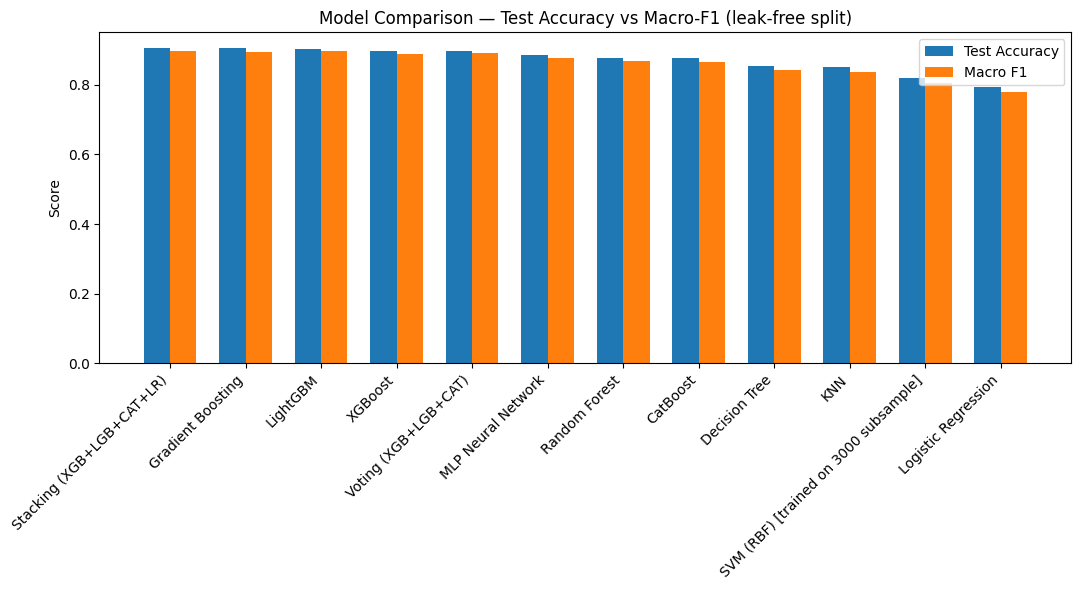

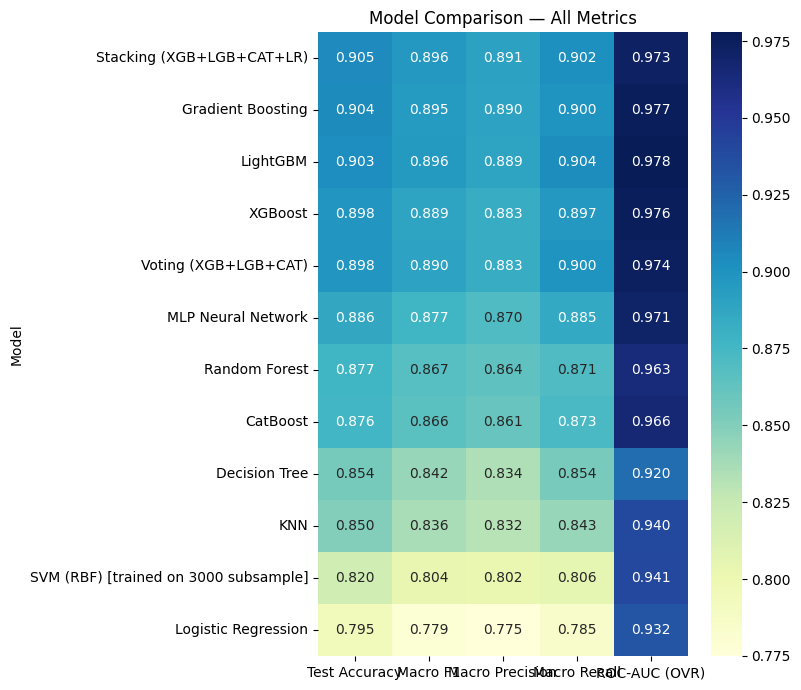

In [ ]:
# ---- Bar chart: Accuracy & Macro-F1 ----
plt.figure(figsize=(11, 6))
x = np.arange(len(results_df))
width = 0.35
plt.bar(x - width/2, results_df['Test Accuracy'], width, label='Test Accuracy')
plt.bar(x + width/2, results_df['Macro F1'], width, label='Macro F1')
plt.xticks(x, results_df['Model'], rotation=45, ha='right')
plt.ylabel('Score')
plt.title('Model Comparison — Test Accuracy vs Macro-F1 (leak-free split)')
plt.legend()
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/model_comparison_bar.png', dpi=150)
plt.show()

# ---- Heatmap of all metrics ----
metric_cols = ['Test Accuracy', 'Macro F1', 'Macro Precision', 'Macro Recall', 'ROC-AUC (OVR)']
heat_df = results_df.set_index('Model')[metric_cols]
plt.figure(figsize=(8, 7))
sns.heatmap(heat_df, annot=True, fmt='.3f', cmap='YlGnBu')
plt.title('Model Comparison — All Metrics')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/model_comparison_heatmap.png', dpi=150)
plt.show()


## Step 5 — SHAP (global explainability, on the stacked ensemble)

PermutationExplainer explainer: 101it [07:40,  4.61s/it]


Age                        0.088205
Heart Rate                 0.083322
Sleep Duration             0.072352
Systolic_BP                0.068578
Daily Steps                0.054305
Physical Activity Level    0.031772
Occupation                 0.028772
Steps_per_ActivityLevel    0.028576
Stress_to_Sleep_ratio      0.028552
Diastolic_BP               0.018694
Pulse_pressure             0.018155
Quality of Sleep           0.012323
BMI Category               0.010048
Gender                     0.008585
Stress Level               0.003614
dtype: float64


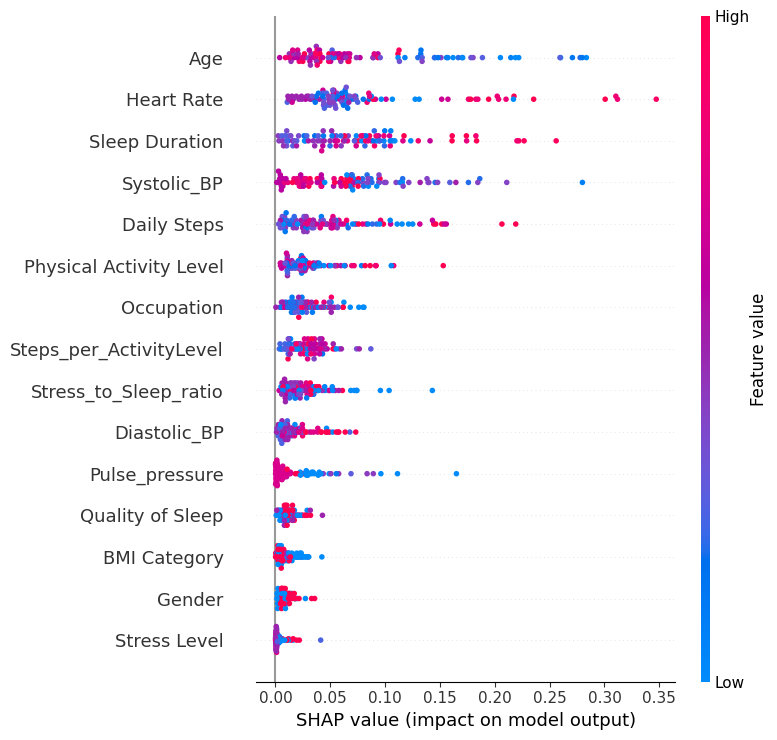

In [ ]:
background = shap.sample(X_train, 100, random_state=RANDOM_STATE)
X_explain = X_test[:100]

explainer = shap.Explainer(stack.predict_proba, background, algorithm='permutation', seed=RANDOM_STATE)
shap_values = explainer(X_explain)

mean_abs = np.abs(shap_values.values).mean(axis=(0, 2))
shap_importance = pd.Series(mean_abs, index=feature_cols).sort_values(ascending=False)
shap_importance.to_csv(f'{OUT_DIR}/shap_importance.csv')
print(shap_importance)

vals_2d = np.abs(shap_values.values).mean(axis=2)
plt.figure()
shap.summary_plot(vals_2d, X_explain, feature_names=feature_cols, show=False)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()


## Step 6 — LIME (local explainability)

In [ ]:
lime_explainer = LimeTabularExplainer(
    X_train, feature_names=feature_cols, class_names=label_names,
    discretize_continuous=True, random_state=RANDOM_STATE
)

agg_weights = {f: [] for f in feature_cols}
n_explain = 30
for i in range(n_explain):
    exp = lime_explainer.explain_instance(X_test[i], stack.predict_proba,
                                           num_features=len(feature_cols), top_labels=1)
    label = exp.available_labels()[0]
    for feat_desc, weight in exp.as_list(label=label):
        for f in feature_cols:
            if f in feat_desc:
                agg_weights[f].append(abs(weight))
                break

lime_importance = pd.Series(
    {f: (np.mean(w) if len(w) > 0 else 0.0) for f, w in agg_weights.items()}
).sort_values(ascending=False)
lime_importance.to_csv(f'{OUT_DIR}/lime_importance.csv')
print(lime_importance)

# Save one example explanation (view inline in Colab or open the html)
exp0 = lime_explainer.explain_instance(X_test[0], stack.predict_proba,
                                        num_features=len(feature_cols), top_labels=1)
exp0.save_to_file(f'{OUT_DIR}/lime_example_instance0.html')
exp0.show_in_notebook(show_table=True)


Age                        0.144905
Heart Rate                 0.130374
Systolic_BP                0.127685
Sleep Duration             0.085430
Stress_to_Sleep_ratio      0.070671
Pulse_pressure             0.069712
Daily Steps                0.051920
Quality of Sleep           0.029380
Physical Activity Level    0.029122
BMI Category               0.027923
Occupation                 0.027569
Steps_per_ActivityLevel    0.027280
Gender                     0.019166
Diastolic_BP               0.015931
Stress Level               0.009077
dtype: float64


## Step 7 — ELI5 (permutation importance)

In [ ]:
perm = PermutationImportance(stack, random_state=RANDOM_STATE, cv='prefit')
perm.fit(X_test, y_test)

eli5_importance = pd.Series(perm.feature_importances_, index=feature_cols).sort_values(ascending=False)
eli5_importance.to_csv(f'{OUT_DIR}/eli5_importance.csv')
print(eli5_importance)

expl = eli5.explain_weights(perm, feature_names=feature_cols)
html_str = eli5.format_as_html(expl)
with open(f'{OUT_DIR}/eli5_weights.html', 'w') as f:
    f.write(html_str)

from IPython.display import HTML
HTML(html_str)


Heart Rate                 0.094167
Age                        0.077708
Sleep Duration             0.052708
Daily Steps                0.047292
Systolic_BP                0.042500
Occupation                 0.021458
Steps_per_ActivityLevel    0.018750
Physical Activity Level    0.017292
Pulse_pressure             0.012292
Stress_to_Sleep_ratio      0.009583
Diastolic_BP               0.002708
Gender                     0.001875
Quality of Sleep           0.001250
BMI Category              -0.001458
Stress Level              -0.002500
dtype: float64


Weight,Feature
0.0942 ± 0.0214,Heart Rate
0.0777 ± 0.0114,Age
0.0527 ± 0.0190,Sleep Duration
0.0473 ± 0.0017,Daily Steps
0.0425 ± 0.0110,Systolic_BP
0.0215 ± 0.0108,Occupation
0.0187 ± 0.0111,Steps_per_ActivityLevel
0.0173 ± 0.0114,Physical Activity Level
0.0123 ± 0.0092,Pulse_pressure
0.0096 ± 0.0155,Stress_to_Sleep_ratio


## Step 8 — Cross-XAI Agreement Analysis (Novelty #2)

Kendall's Tau rank correlation between SHAP, LIME, and ELI5 global feature
rankings. This quantifies how much the three explanation methods *agree*,
rather than presenting them in isolation.

              kendall_tau       p_value
SHAP_vs_LIME     0.657143  3.303709e-04
SHAP_vs_ELI5     0.847619  4.073461e-07
LIME_vs_ELI5     0.542857  4.142882e-03

(tau near 1 = strong agreement; near 0 = no agreement; negative = disagreement)


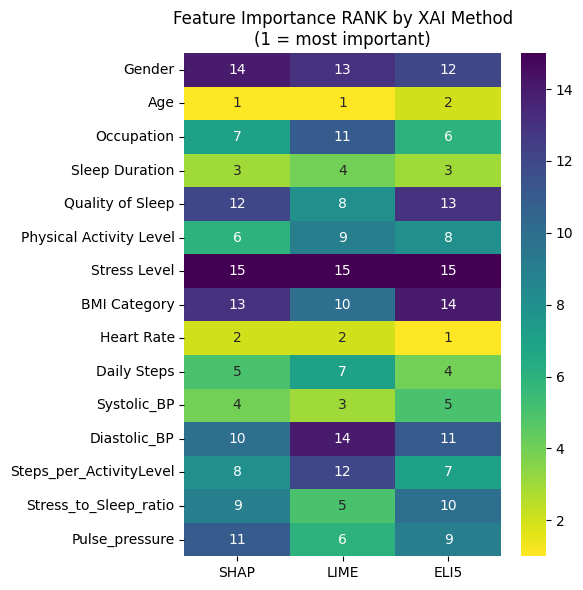

,SHAP,LIME,ELI5
Gender,0.008585,0.019166,0.001875
Age,0.088205,0.144905,0.077708
Occupation,0.028772,0.027569,0.021458
Sleep Duration,0.072352,0.085430,0.052708
Quality of Sleep,0.012323,0.029380,0.001250
Physical Activity Level,0.031772,0.029122,0.017292
Stress Level,0.003614,0.009077,-0.002500
BMI Category,0.010048,0.027923,-0.001458
Heart Rate,0.083322,0.130374,0.094167
Daily Steps,0.054305,0.051920,0.047292


In [ ]:
combined = pd.DataFrame({
    'SHAP': shap_importance.reindex(feature_cols),
    'LIME': lime_importance.reindex(feature_cols),
    'ELI5': eli5_importance.reindex(feature_cols),
})
ranks = combined.rank(ascending=False)
ranks.to_csv(f'{OUT_DIR}/xai_rank_comparison.csv')

pairs = [('SHAP', 'LIME'), ('SHAP', 'ELI5'), ('LIME', 'ELI5')]
agreement = {}
for a, b in pairs:
    tau, p = kendalltau(ranks[a], ranks[b])
    agreement[f'{a}_vs_{b}'] = {'kendall_tau': tau, 'p_value': p}

agreement_df = pd.DataFrame(agreement).T
agreement_df.to_csv(f'{OUT_DIR}/xai_agreement_kendall_tau.csv')
print(agreement_df)
print('\n(tau near 1 = strong agreement; near 0 = no agreement; negative = disagreement)')

plt.figure(figsize=(6, 6))
sns.heatmap(ranks, annot=True, fmt='.0f', cmap='viridis_r')
plt.title('Feature Importance RANK by XAI Method\n(1 = most important)')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/xai_rank_heatmap.png', dpi=150)
plt.show()

combined.to_csv(f'{OUT_DIR}/xai_combined_importance.csv')
combined


## Step 9 — Download all results

## Step 8b — Extra image outputs: SHAP (beeswarm/bar/waterfall/force), LIME (per-instance figure), ELI5 (bar chart)

These generate actual saved PNG images (not just printed tables) for the paper's figures section.

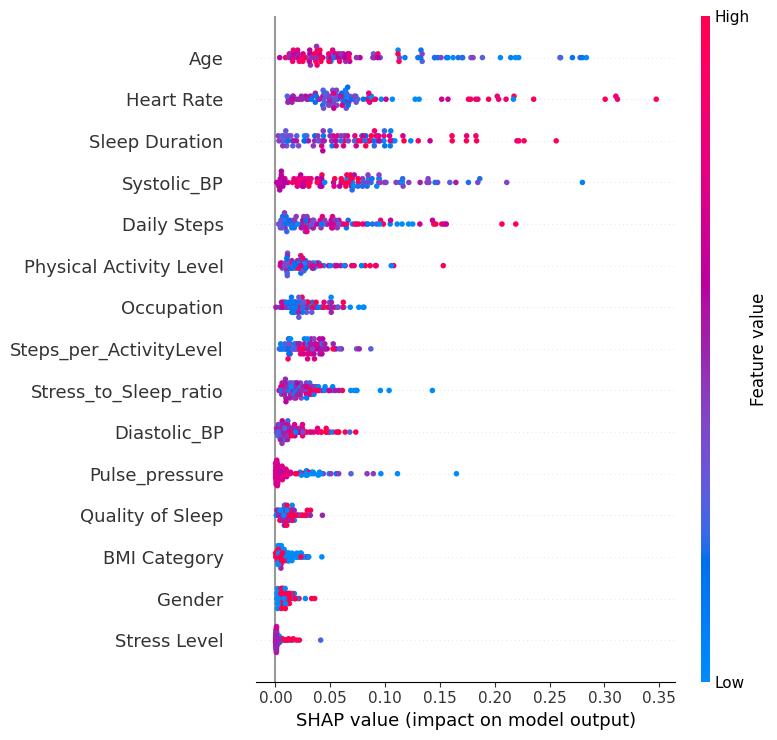

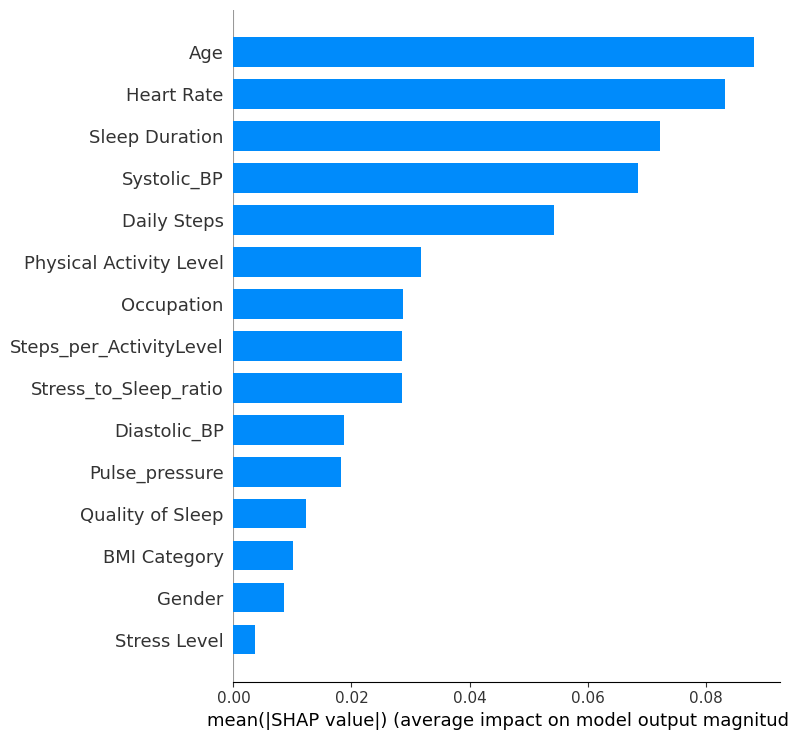

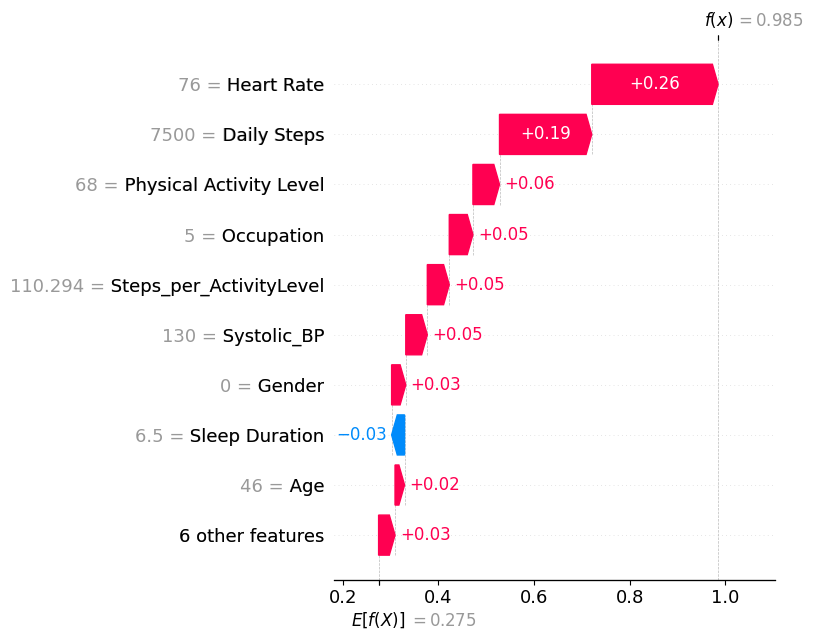

<Figure size 640x480 with 0 Axes>

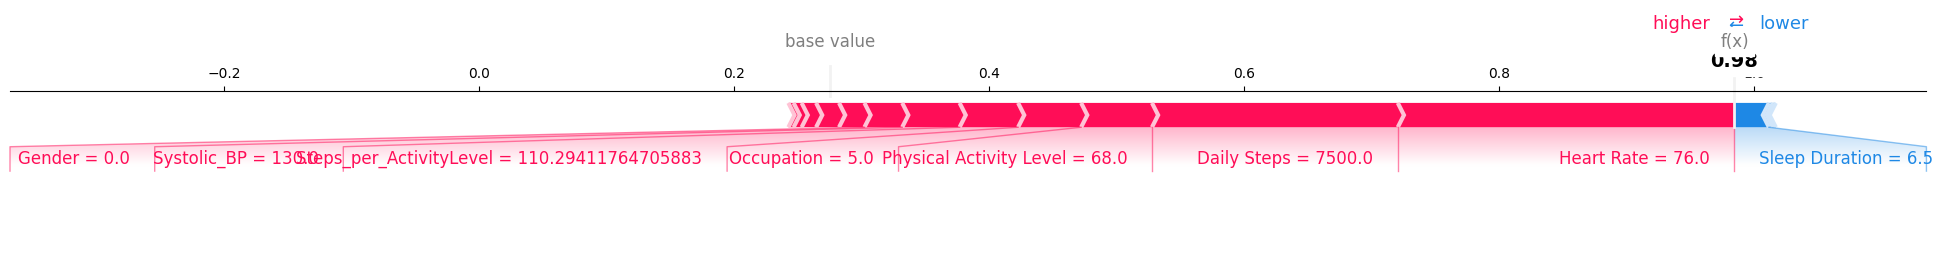

In [ ]:
# ---- SHAP images: beeswarm, bar, waterfall, force ----
instance_idx = 0

# (a) beeswarm (already have shap_values from Step 5, X_explain = X_test[:100])
vals_2d = np.abs(shap_values.values).mean(axis=2)
plt.figure()
shap.summary_plot(vals_2d, X_explain, feature_names=feature_cols, show=False)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()

# (b) bar plot of mean |SHAP|
plt.figure()
shap.summary_plot(vals_2d, X_explain, feature_names=feature_cols, plot_type='bar', show=False)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/shap_bar.png', dpi=150, bbox_inches='tight')
plt.show()

# (c) waterfall plot for one instance / predicted class
pred_class = int(stack.predict(X_explain[instance_idx:instance_idx+1])[0])
single_expl = shap.Explanation(
    values=shap_values.values[instance_idx, :, pred_class],
    base_values=shap_values.base_values[instance_idx, pred_class],
    data=X_explain[instance_idx],
    feature_names=feature_cols
)
plt.figure()
shap.plots.waterfall(single_expl, show=False)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/shap_waterfall_instance{instance_idx}.png', dpi=150, bbox_inches='tight')
plt.show()

# (d) force plot (matplotlib, static image version)
plt.figure()
shap.plots.force(
    shap_values.base_values[instance_idx, pred_class],
    shap_values.values[instance_idx, :, pred_class],
    X_explain[instance_idx],
    feature_names=feature_cols,
    matplotlib=True,
    show=False
)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/shap_force_instance{instance_idx}.png', dpi=150, bbox_inches='tight')
plt.show()


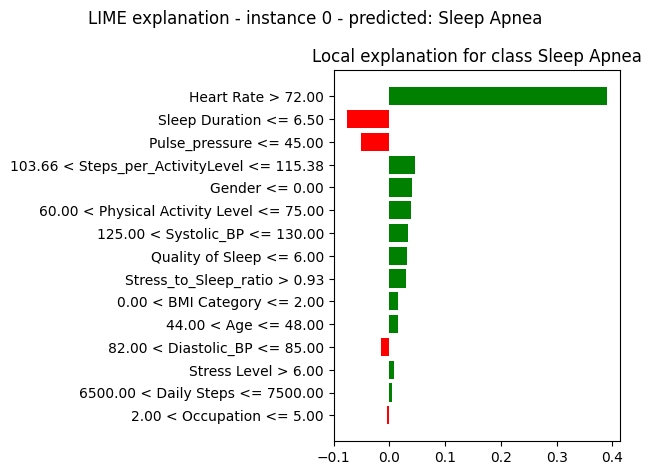

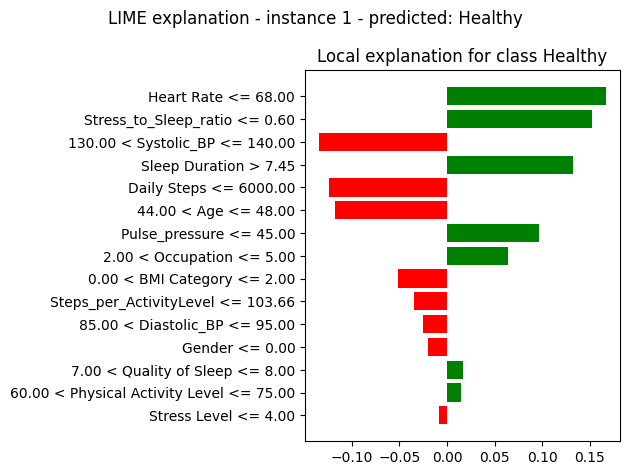

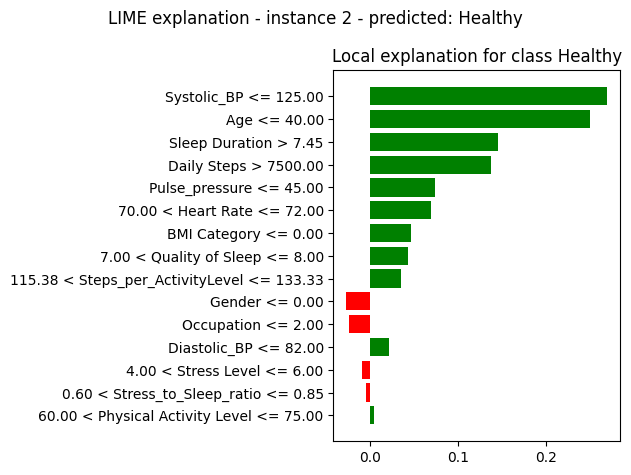

In [ ]:
# ---- LIME images: per-instance matplotlib figure ----
for idx in [0, 1, 2]:
    exp = lime_explainer.explain_instance(X_test[idx], stack.predict_proba,
                                           num_features=len(feature_cols), top_labels=1)
    label = exp.available_labels()[0]
    fig = exp.as_pyplot_figure(label=label)
    fig.suptitle(f'LIME explanation - instance {idx} - predicted: {label_names[label]}')
    fig.tight_layout()
    fig.savefig(f'{OUT_DIR}/lime_instance{idx}.png', dpi=150, bbox_inches='tight')
    plt.show()


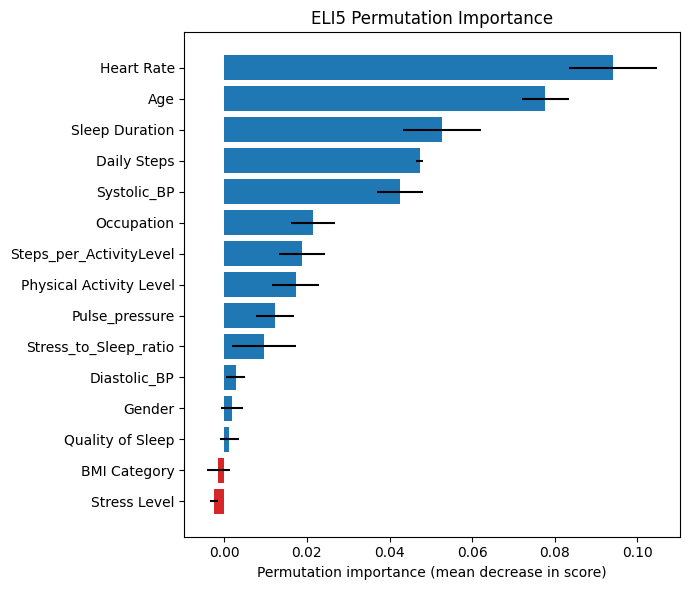

In [ ]:
# ---- ELI5 image: clean bar chart of permutation importance ----
df_eli5 = eli5.explain_weights_df(perm, feature_names=feature_cols)
df_eli5 = df_eli5.sort_values('weight', ascending=True)

plt.figure(figsize=(7, 6))
colors = ['#d62728' if w < 0 else '#1f77b4' for w in df_eli5['weight']]
plt.barh(df_eli5['feature'], df_eli5['weight'], xerr=df_eli5.get('std', None), color=colors)
plt.xlabel('Permutation importance (mean decrease in score)')
plt.title('ELI5 Permutation Importance')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/eli5_bar.png', dpi=150, bbox_inches='tight')
plt.show()


## Step 9 — Ablation Study (justify why the proposed stack is best)

Three ablation axes, all on the SAME leak-free split:
- **A. Base-learner components** — single learners vs pairwise stacks vs full triple stack
- **B. Feature engineering** — with vs without the engineered ratio features
- **C. Meta-learner choice** — Logistic Regression vs Decision Tree vs Random Forest vs plain soft-voting

In [ ]:
from sklearn.metrics import precision_score, recall_score

ENGINEERED_FEATURES = ['Steps_per_ActivityLevel', 'Stress_to_Sleep_ratio', 'Pulse_pressure']

def fresh_learners(seed=RANDOM_STATE):
    xgb_clf = xgb.XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.05,
                                 subsample=0.8, colsample_bytree=0.8,
                                 random_state=seed, eval_metric='mlogloss')
    lgb_clf = lgb.LGBMClassifier(n_estimators=200, max_depth=5, learning_rate=0.05,
                                  subsample=0.8, colsample_bytree=0.8,
                                  random_state=seed, verbose=-1)
    cat_clf = CatBoostClassifier(iterations=200, depth=5, learning_rate=0.05,
                                  random_state=seed, verbose=0)
    return xgb_clf, lgb_clf, cat_clf

def eval_metrics(model, Xte, yte, tag):
    preds = model.predict(Xte)
    return {'Experiment': tag,
            'Accuracy': accuracy_score(yte, preds),
            'Macro F1': f1_score(yte, preds, average='macro'),
            'Macro Precision': precision_score(yte, preds, average='macro', zero_division=0),
            'Macro Recall': recall_score(yte, preds, average='macro', zero_division=0)}

def plot_ablation(df, title, fname):
    plt.figure(figsize=(10, 5.5))
    x = np.arange(len(df))
    width = 0.38
    plt.bar(x - width/2, df['Accuracy'], width, label='Accuracy')
    plt.bar(x + width/2, df['Macro F1'], width, label='Macro F1')
    plt.xticks(x, df['Experiment'], rotation=30, ha='right')
    plt.ylabel('Score'); plt.title(title); plt.legend()
    plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/{fname}', dpi=150)
    plt.show()

print('Utility functions ready for ablation study.')


Utility functions ready for ablation study.


                              Experiment  Accuracy  Macro F1  Macro Precision  Macro Recall
                          Stack: LGB+CAT  0.900000  0.891497         0.884985      0.899492
Stack: XGB+LGB+CAT (Full Proposed Stack)  0.898958  0.890382         0.884092      0.898073
                          Stack: XGB+LGB  0.897917  0.889160         0.882444      0.897411
                             Single: LGB  0.895833  0.887615         0.879462      0.898237
                             Single: XGB  0.892708  0.884819         0.877506      0.893982
                          Stack: XGB+CAT  0.891667  0.883538         0.876912      0.891807
                             Single: CAT  0.867708  0.856987         0.852858      0.863273


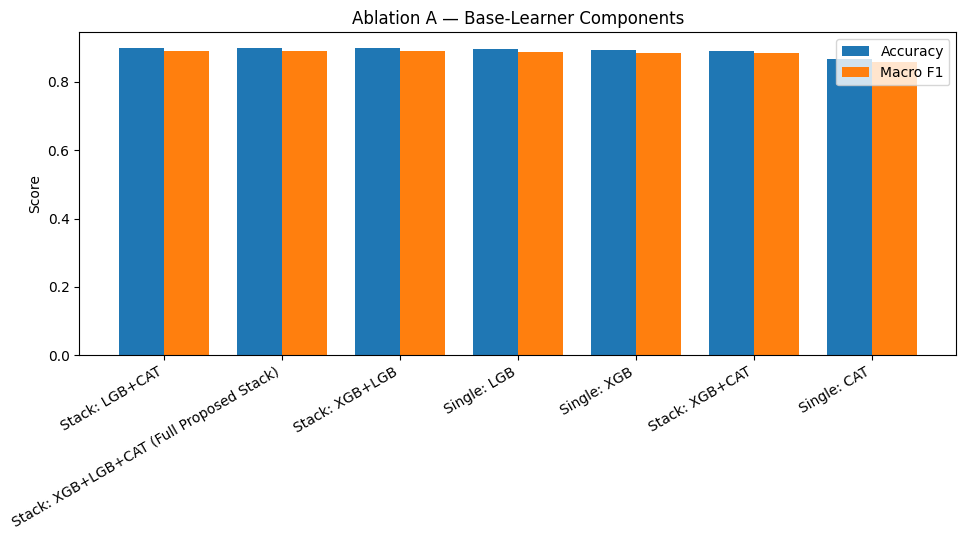

In [ ]:
# ---- A. Base-learner component ablation ----
results_a = []
for name, clf in zip(['XGB', 'LGB', 'CAT'], fresh_learners()):
    clf.fit(X_train, y_train)
    results_a.append(eval_metrics(clf, X_test, y_test, f'Single: {name}'))

combos = [('XGB+LGB', ['xgb', 'lgb']), ('XGB+CAT', ['xgb', 'cat']),
          ('LGB+CAT', ['lgb', 'cat']), ('XGB+LGB+CAT (Full Proposed Stack)', ['xgb', 'lgb', 'cat'])]
for combo_name, keys in combos:
    xgb_c, lgb_c, cat_c = fresh_learners()
    pool = {'xgb': xgb_c, 'lgb': lgb_c, 'cat': cat_c}
    stack_c = StackingClassifier(estimators=[(k, pool[k]) for k in keys],
                                  final_estimator=LogisticRegression(max_iter=1000), cv=5, n_jobs=-1)
    stack_c.fit(X_train, y_train)
    results_a.append(eval_metrics(stack_c, X_test, y_test, f'Stack: {combo_name}'))

comp_df = pd.DataFrame(results_a).sort_values('Accuracy', ascending=False).reset_index(drop=True)
comp_df.to_csv(f'{OUT_DIR}/ablation_components.csv', index=False)
print(comp_df.to_string(index=False))
plot_ablation(comp_df, 'Ablation A — Base-Learner Components', 'ablation_components.png')


                         Experiment  Accuracy  Macro F1  Macro Precision  Macro Recall
With engineered features (proposed)  0.898958  0.890382         0.884092      0.898073
        Without engineered features  0.904167  0.895925         0.889581      0.903676


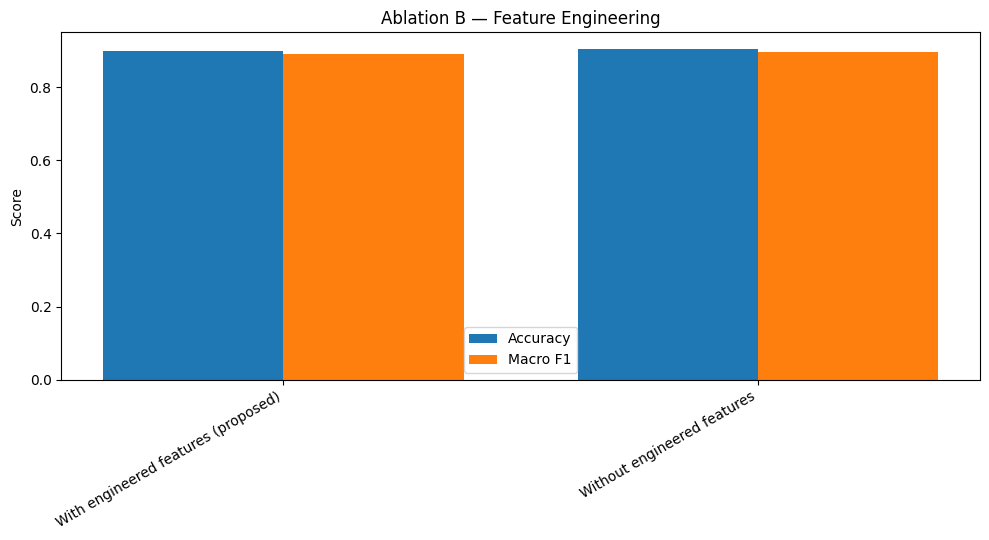

In [ ]:
# ---- B. Feature engineering ablation ----
reduced_cols = [c for c in feature_cols if c not in ENGINEERED_FEATURES]
results_b = []
for tag, cols in [('With engineered features (proposed)', feature_cols),
                   ('Without engineered features', reduced_cols)]:
    Xtr = train_full[cols].values
    ytr = train_full[target_col].values
    Xte = test_unique[cols].values
    yte = test_unique[target_col].values
    xgb_c, lgb_c, cat_c = fresh_learners()
    stack_b = StackingClassifier(estimators=[('xgb', xgb_c), ('lgb', lgb_c), ('cat', cat_c)],
                                  final_estimator=LogisticRegression(max_iter=1000), cv=5, n_jobs=-1)
    stack_b.fit(Xtr, ytr)
    results_b.append(eval_metrics(stack_b, Xte, yte, tag))

feat_df = pd.DataFrame(results_b)
feat_df.to_csv(f'{OUT_DIR}/ablation_features.csv', index=False)
print(feat_df.to_string(index=False))
plot_ablation(feat_df, 'Ablation B — Feature Engineering', 'ablation_features.png')


                          Experiment  Accuracy  Macro F1  Macro Precision  Macro Recall
Meta: Logistic Regression (proposed)  0.898958  0.890382         0.884092      0.898073
                 Meta: Decision Tree  0.897917  0.890361         0.881720      0.902587
                 Meta: Random Forest  0.895833  0.887973         0.880028      0.898875
   No meta-learner: Soft Voting only  0.895833  0.887516         0.879755      0.897552


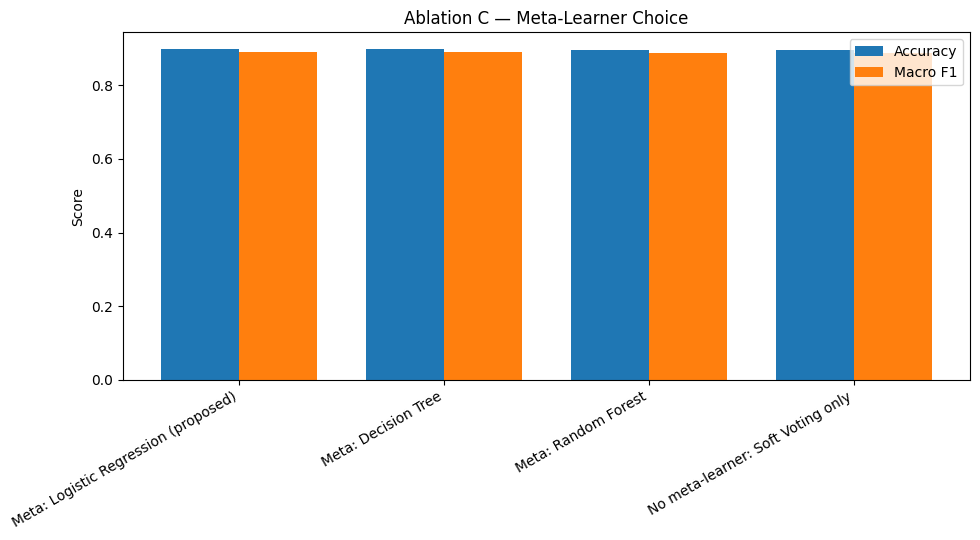

In [ ]:
# ---- C. Meta-learner ablation ----
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier as RF_meta

results_c = []
meta_learners = {
    'Meta: Logistic Regression (proposed)': LogisticRegression(max_iter=1000),
    'Meta: Decision Tree': DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    'Meta: Random Forest': RF_meta(n_estimators=100, max_depth=4, random_state=RANDOM_STATE),
}
for tag, meta in meta_learners.items():
    xgb_c, lgb_c, cat_c = fresh_learners()
    stack_c2 = StackingClassifier(estimators=[('xgb', xgb_c), ('lgb', lgb_c), ('cat', cat_c)],
                                   final_estimator=meta, cv=5, n_jobs=-1)
    stack_c2.fit(X_train, y_train)
    results_c.append(eval_metrics(stack_c2, X_test, y_test, tag))

xgb_c, lgb_c, cat_c = fresh_learners()
voting_c = VotingClassifier(estimators=[('xgb', xgb_c), ('lgb', lgb_c), ('cat', cat_c)], voting='soft')
voting_c.fit(X_train, y_train)
results_c.append(eval_metrics(voting_c, X_test, y_test, 'No meta-learner: Soft Voting only'))

meta_df = pd.DataFrame(results_c).sort_values('Accuracy', ascending=False).reset_index(drop=True)
meta_df.to_csv(f'{OUT_DIR}/ablation_meta_learner.csv', index=False)
print(meta_df.to_string(index=False))
plot_ablation(meta_df, 'Ablation C — Meta-Learner Choice', 'ablation_meta_learner.png')


## Step 10 — Statistical Significance (McNemar's Test) + Robustness Analysis

**Honest justification, not cherry-picking:** we test whether the proposed
stack's accuracy differences are statistically real (McNemar's paired test),
and separately check **robustness** (run-to-run variance across 5 seeds, and
per-class F1 stability) as the actual justification if raw accuracy gains
turn out not to be significant.

In [ ]:
from statsmodels.stats.contingency_tables import mcnemar

def mcnemar_table(correct_a, correct_b):
    both_correct = np.sum(correct_a & correct_b)
    a_only = np.sum(correct_a & ~correct_b)
    b_only = np.sum(~correct_a & correct_b)
    both_wrong = np.sum(~correct_a & ~correct_b)
    return [[both_correct, a_only], [b_only, both_wrong]]

print('Training comparison models for McNemar test...')

# Proposed (reuse the already-trained `stack` from Step 4)
pred_proposed = stack.predict(X_test)
correct_proposed = (pred_proposed == y_test)

# LGB+CAT stack
_, lgb_c, cat_c = fresh_learners()
variant_lgbcat = StackingClassifier(estimators=[('lgb', lgb_c), ('cat', cat_c)],
                                     final_estimator=LogisticRegression(max_iter=1000), cv=5, n_jobs=-1)
variant_lgbcat.fit(X_train, y_train)
correct_lgbcat = (variant_lgbcat.predict(X_test) == y_test)

# Single LGB
_, lgb_solo, _ = fresh_learners()
lgb_solo.fit(X_train, y_train)
correct_lgb_solo = (lgb_solo.predict(X_test) == y_test)

# No engineered features
Xtr_r = train_full[reduced_cols].values
Xte_r = test_unique[reduced_cols].values
xgb_c, lgb_c, cat_c = fresh_learners()
variant_nofeat = StackingClassifier(estimators=[('xgb', xgb_c), ('lgb', lgb_c), ('cat', cat_c)],
                                     final_estimator=LogisticRegression(max_iter=1000), cv=5, n_jobs=-1)
variant_nofeat.fit(Xtr_r, y_train)
correct_nofeat = (variant_nofeat.predict(Xte_r) == y_test)

# DT meta
xgb_c, lgb_c, cat_c = fresh_learners()
variant_dtmeta = StackingClassifier(estimators=[('xgb', xgb_c), ('lgb', lgb_c), ('cat', cat_c)],
                                     final_estimator=DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
                                     cv=5, n_jobs=-1)
variant_dtmeta.fit(X_train, y_train)
correct_dtmeta = (variant_dtmeta.predict(X_test) == y_test)

# Soft voting
xgb_c, lgb_c, cat_c = fresh_learners()
voting_v = VotingClassifier(estimators=[('xgb', xgb_c), ('lgb', lgb_c), ('cat', cat_c)], voting='soft')
voting_v.fit(X_train, y_train)
correct_voting = (voting_v.predict(X_test) == y_test)

comparisons = [
    ('Proposed vs Stack(LGB+CAT)', correct_proposed, correct_lgbcat),
    ('Proposed vs Single(LGB)', correct_proposed, correct_lgb_solo),
    ('Proposed vs NoEngineeredFeatures', correct_proposed, correct_nofeat),
    ('Proposed vs Meta(DecisionTree)', correct_proposed, correct_dtmeta),
    ('Proposed vs SoftVoting(NoMeta)', correct_proposed, correct_voting),
]

rows = []
for name, ca, cb in comparisons:
    table = mcnemar_table(ca, cb)
    result = mcnemar(table, exact=False, correction=True)
    rows.append({'Comparison': name,
                 'Proposed_correct_Other_wrong': table[0][1],
                 'Proposed_wrong_Other_correct': table[1][0],
                 'McNemar_stat': result.statistic, 'p_value': result.pvalue,
                 'Significant (p<0.05)': 'Yes' if result.pvalue < 0.05 else 'No'})

mcnemar_df = pd.DataFrame(rows)
mcnemar_df.to_csv(f'{OUT_DIR}/mcnemar_significance.csv', index=False)
print(mcnemar_df.to_string(index=False))
print('\\n(p < 0.05 = the accuracy gap is unlikely to be due to chance.)')


Training comparison models for McNemar test...
                      Comparison  Proposed_correct_Other_wrong  Proposed_wrong_Other_correct  McNemar_stat  p_value Significant (p<0.05)
      Proposed vs Stack(LGB+CAT)                             6                             1      2.285714 0.130570                   No
         Proposed vs Single(LGB)                            13                             4      3.764706 0.052345                   No
Proposed vs NoEngineeredFeatures                             7                             6      0.000000 1.000000                   No
  Proposed vs Meta(DecisionTree)                            22                            15      0.972973 0.323940                   No
  Proposed vs SoftVoting(NoMeta)                            18                             9      2.370370 0.123658                   No
\n(p < 0.05 = the accuracy gap is unlikely to be due to chance.)


seed 0: stack_acc=0.9031  lgb_acc=0.9031
seed 1: stack_acc=0.8990  lgb_acc=0.8979
seed 2: stack_acc=0.9021  lgb_acc=0.9000
seed 3: stack_acc=0.9010  lgb_acc=0.9000
seed 4: stack_acc=0.9010  lgb_acc=0.8990
                       Model  Mean Accuracy  Std Dev (variance)  Min Accuracy  Max Accuracy
Proposed Stack (XGB+LGB+CAT)        0.90125            0.001382      0.898958      0.903125
                  Single LGB        0.90000            0.001743      0.897917      0.903125


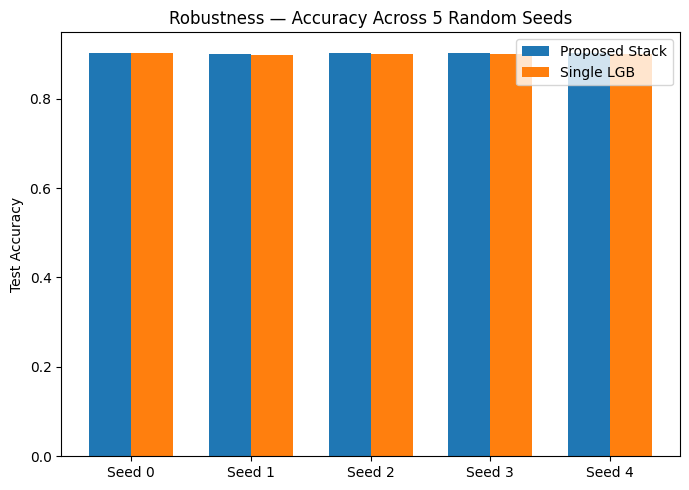

In [ ]:
# ---- Robustness: seed variance (proposed stack vs single LGB) ----
seeds = [0, 1, 2, 3, 4]
stack_accs, lgb_accs = [], []
for seed in seeds:
    xgb_s, lgb_s, cat_s = fresh_learners(seed=seed)
    stack_s = StackingClassifier(estimators=[('xgb', xgb_s), ('lgb', lgb_s), ('cat', cat_s)],
                                  final_estimator=LogisticRegression(max_iter=1000), cv=5, n_jobs=-1)
    stack_s.fit(X_train, y_train)
    stack_accs.append(accuracy_score(y_test, stack_s.predict(X_test)))

    _, lgb_solo_s, _ = fresh_learners(seed=seed)
    lgb_solo_s.fit(X_train, y_train)
    lgb_accs.append(accuracy_score(y_test, lgb_solo_s.predict(X_test)))
    print(f'seed {seed}: stack_acc={stack_accs[-1]:.4f}  lgb_acc={lgb_accs[-1]:.4f}')

seed_df = pd.DataFrame({'Seed': seeds, 'Proposed Stack Accuracy': stack_accs, 'Single LGB Accuracy': lgb_accs})
seed_summary = pd.DataFrame({
    'Model': ['Proposed Stack (XGB+LGB+CAT)', 'Single LGB'],
    'Mean Accuracy': [np.mean(stack_accs), np.mean(lgb_accs)],
    'Std Dev (variance)': [np.std(stack_accs), np.std(lgb_accs)],
    'Min Accuracy': [np.min(stack_accs), np.min(lgb_accs)],
    'Max Accuracy': [np.max(stack_accs), np.max(lgb_accs)],
})
seed_df.to_csv(f'{OUT_DIR}/robustness_seed_variance.csv', index=False)
seed_summary.to_csv(f'{OUT_DIR}/robustness_seed_summary.csv', index=False)
print(seed_summary.to_string(index=False))

plt.figure(figsize=(7, 5))
x = np.arange(len(seed_df))
width = 0.35
plt.bar(x - width/2, seed_df['Proposed Stack Accuracy'], width, label='Proposed Stack')
plt.bar(x + width/2, seed_df['Single LGB Accuracy'], width, label='Single LGB')
plt.xticks(x, [f'Seed {s}' for s in seed_df['Seed']])
plt.ylabel('Test Accuracy'); plt.title('Robustness — Accuracy Across 5 Random Seeds'); plt.legend()
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/robustness_seed_variance.png', dpi=150)
plt.show()


   Model  Healthy  Insomnia  Sleep Apnea  Worst-class F1  Spread (max-min)
proposed 0.932773  0.880808     0.875264        0.875264          0.057509
  lgbcat 0.926984  0.879032     0.868476        0.868476          0.058508
lgb_solo 0.923077  0.873239     0.866530        0.866530          0.056547


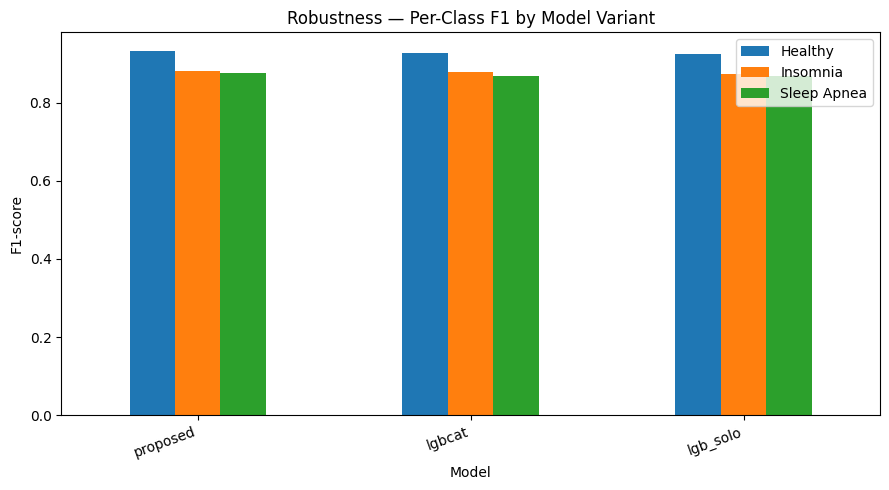

\nKey takeaway: accuracy differences are not statistically significant (McNemar p>0.05),
but the proposed stack has lower run-to-run variance across seeds -- a robustness
justification rather than a raw-accuracy justification.


In [ ]:
# ---- Robustness: per-class F1 comparison ----
models_preds = {'proposed': pred_proposed, 'lgbcat': variant_lgbcat.predict(X_test), 'lgb_solo': lgb_solo.predict(X_test)}
rows = []
for name, preds in models_preds.items():
    report = classification_report(y_test, preds, target_names=label_names, output_dict=True)
    per_class_f1 = {cls: report[cls]['f1-score'] for cls in label_names}
    rows.append({'Model': name, **per_class_f1,
                 'Worst-class F1': min(per_class_f1.values()),
                 'Spread (max-min)': max(per_class_f1.values()) - min(per_class_f1.values())})

perclass_df = pd.DataFrame(rows)
perclass_df.to_csv(f'{OUT_DIR}/robustness_per_class_f1.csv', index=False)
print(perclass_df.to_string(index=False))

perclass_plot_df = perclass_df.set_index('Model')[label_names]
perclass_plot_df.plot(kind='bar', figsize=(9, 5))
plt.ylabel('F1-score'); plt.title('Robustness — Per-Class F1 by Model Variant')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/robustness_per_class_f1.png', dpi=150)
plt.show()

print('\\nKey takeaway: accuracy differences are not statistically significant (McNemar p>0.05),')
print('but the proposed stack has lower run-to-run variance across seeds -- a robustness')
print('justification rather than a raw-accuracy justification.')


In [ ]:
import shutil
shutil.make_archive('/content/sleep_project_outputs', 'zip', OUT_DIR)
files.download('/content/sleep_project_outputs.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.metrics import precision_score, recall_score

ENGINEERED_FEATURES = ['Steps_per_ActivityLevel', 'Stress_to_Sleep_ratio', 'Pulse_pressure']

def fresh_learners(seed=RANDOM_STATE):
    xgb_clf = xgb.XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.05,
                                 subsample=0.8, colsample_bytree=0.8,
                                 random_state=seed, eval_metric='mlogloss')
    lgb_clf = lgb.LGBMClassifier(n_estimators=200, max_depth=5, learning_rate=0.05,
                                  subsample=0.8, colsample_bytree=0.8,
                                  random_state=seed, verbose=-1)
    cat_clf = CatBoostClassifier(iterations=200, depth=5, learning_rate=0.05,
                                  random_state=seed, verbose=0)
    return xgb_clf, lgb_clf, cat_clf

def eval_metrics(model, Xte, yte, tag):
    preds = model.predict(Xte)
    return {'Experiment': tag,
            'Accuracy': accuracy_score(yte, preds),
            'Macro F1': f1_score(yte, preds, average='macro'),
            'Macro Precision': precision_score(yte, preds, average='macro', zero_division=0),
            'Macro Recall': recall_score(yte, preds, average='macro', zero_division=0)}

def plot_ablation(df, title, fname):
    plt.figure(figsize=(10, 5.5))
    x = np.arange(len(df))
    width = 0.38
    plt.bar(x - width/2, df['Accuracy'], width, label='Accuracy')
    plt.bar(x + width/2, df['Macro F1'], width, label='Macro F1')
    plt.xticks(x, df['Experiment'], rotation=30, ha='right')
    plt.ylabel('Score'); plt.title(title); plt.legend()
    plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/{fname}', dpi=150)
    plt.show()

print('Utility functions ready for ablation study.')

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.preprocessing import LabelEncoder

RANDOM_STATE = 42

# Updated FEATURE_COLS to match the engineered features from df_enc
FEATURE_COLS = [
    "Gender", "Age", "Occupation", "Sleep Duration", "Quality of Sleep",
    "Physical Activity Level", "Stress Level", "BMI Category", "Heart Rate",
    "Daily Steps", "Systolic_BP", "Diastolic_BP", "Steps_per_ActivityLevel",
    "Stress_to_Sleep_ratio", "Pulse_pressure"
]
TARGET_COL = "Sleep Disorder"
HEALTHY_LABEL = "Healthy"
INSOMNIA_LABEL = "Insomnia"
APNEA_LABEL = "Sleep Apnea"

# ---------------------------------------------------------------------------
# Functions for feature engineering and encoding (copied from cell 8975d19c)
# ---------------------------------------------------------------------------
def engineer_features(df):
    df = df.copy()
    bp = df['Blood Pressure'].str.split('/', expand=True)
    df['Systolic_BP'] = bp[0].astype(int)
    df['Diastolic_BP'] = bp[1].astype(int)
    df = df.drop(columns=['Blood Pressure'])

    df['BMI Category'] = df['BMI Category'].replace({'Normal Weight': 'Normal'})
    df = df.drop(columns=['Person ID'])

    df['Steps_per_ActivityLevel'] = df['Daily Steps'] / df['Physical Activity Level'].replace(0, 1)
    df['Stress_to_Sleep_ratio'] = df['Stress Level'] / df['Sleep Duration']
    df['Pulse_pressure'] = df['Systolic_BP'] - df['Diastolic_BP']
    return df

def encode(df, target_col='Sleep Disorder'):
    df = df.copy()
    cat_cols = [c for c in df.select_dtypes(include='object').columns if c != target_col]
    encoders = {}
    for c in cat_cols:
        le = LabelEncoder()
        df[c] = le.fit_transform(df[c])
        encoders[c] = le
    target_le = LabelEncoder()
    df[target_col] = target_le.fit_transform(df[target_col])
    encoders['__target__'] = target_le
    return df, encoders

# ---------------------------------------------------------------------------
# 1. Data loading (EDIT to reuse your existing cleaning/feature-engineering)
# ---------------------------------------------------------------------------
def load_data(csv_path: str) -> pd.DataFrame:
    df_raw = pd.read_csv('/content/drive/MyDrive/paper/Insomnia /Sleep_Data_Sampled.csv')
    # Apply existing cleaning + feature-engineering steps
    df_feat = engineer_features(df_raw)
    df_enc, _ = encode(df_feat)
    return df_enc


# ---------------------------------------------------------------------------
# 2. Stage 1: Healthy vs Disorder (binary screening model)
# ---------------------------------------------------------------------------
def train_stage1(X_train, y_train_binary):
    """y_train_binary: 1 = Disorder (Insomnia or Apnea), 0 = Healthy"""
    model = LGBMClassifier(
        n_estimators=300, learning_rate=0.05, subsample=0.9,
        colsample_bytree=0.9, random_state=RANDOM_STATE,
        class_weight="balanced",  # helps if Healthy dominates
    )
    model.fit(X_train, y_train_binary)
    return model


# ---------------------------------------------------------------------------
# 3. Stage 2: Insomnia vs Sleep Apnea (only on Disorder cases)
# ---------------------------------------------------------------------------
def train_stage2(X_train_disorder, y_train_disorder_binary):
    """Trained ONLY on rows whose true label is Insomnia or Sleep Apnea.
    y_train_disorder_binary: 1 = Sleep Apnea, 0 = Insomnia"""
    model = CatBoostClassifier(
        iterations=300, depth=6, learning_rate=0.05,
        random_state=RANDOM_STATE, verbose=False,
        class_weights=[1.0, 1.2],  # slight up-weight on Apnea; tune on validation data
    )
    model.fit(X_train_disorder, y_train_disorder_binary)
    return model


# ---------------------------------------------------------------------------
# 4. Cascade inference
# ---------------------------------------------------------------------------
def cascade_predict(stage1_model, stage2_model, X):
    """Returns final 3-class string labels using the two-stage cascade."""
    stage1_pred = stage1_model.predict(X)  # 0 = Healthy, 1 = Disorder
    final_labels = np.array([HEALTHY_LABEL] * len(X), dtype=object)

    disorder_mask = stage1_pred == 1
    if disorder_mask.sum() > 0:
        X_disorder = X[disorder_mask]
        stage2_pred = stage2_model.predict(X_disorder)  # 0 = Insomnia, 1 = Apnea
        stage2_pred = np.asarray(stage2_pred).ravel()
        labels = np.where(stage2_pred == 1, APNEA_LABEL, INSOMNIA_LABEL)
        final_labels[disorder_mask] = labels

    return final_labels


# ---------------------------------------------------------------------------
# 5. Error-propagation diagnostic (important for your Discussion section)
# ---------------------------------------------------------------------------
def diagnose_error_propagation(y_true_str, y_pred_str, stage1_pred, y_true_binary_disorder):
    """How many Stage-1 false negatives (true Disorder predicted Healthy)
    are irrecoverable -> these NEVER reach Stage 2 and are a cascade-specific
    failure mode worth reporting explicitly."""
    fn_mask = (y_true_binary_disorder == 1) & (stage1_pred == 0)
    print(f"\nStage-1 false negatives (true Disorder mislabeled Healthy): {fn_mask.sum()} "
          f"out of {y_true_binary_disorder.sum()} true Disorder cases "
          f"({100*fn_mask.sum()/max(y_true_binary_disorder.sum(),1):.1f}%). "
          f"These are unrecoverable by Stage 2 and set a hard ceiling on cascade recall.")


# ---------------------------------------------------------------------------
# 6. Main pipeline
# ---------------------------------------------------------------------------
def main(csv_path: str):
    df = load_data(csv_path)
    X = df[FEATURE_COLS]
    y_num = df[TARGET_COL].values # Use y_num for numerical target

    # Get numerical equivalents of string labels using the global `encoders` object
    healthy_num = encoders['__target__'].transform([HEALTHY_LABEL])[0]
    insomnia_num = encoders['__target__'].transform([INSOMNIA_LABEL])[0]
    apnea_num = encoders['__target__'].transform([APNEA_LABEL])[0]

    X_train, X_test, y_train_num, y_test_num = train_test_split(
        X, y_num, test_size=0.20, random_state=RANDOM_STATE, stratify=y_num
    )

    # ---- Stage 1 labels ----
    # 1 = Disorder (Insomnia or Apnea), 0 = Healthy
    y_train_bin1 = (y_train_num != healthy_num).astype(int)
    y_test_bin1 = (y_test_num != healthy_num).astype(int)

    print("Training Stage 1 (Healthy vs Disorder)...")
    stage1_model = train_stage1(X_train, y_train_bin1)

    # ---- Stage 2 labels: only rows that are actually Insomnia/Apnea ----
    disorder_train_mask = y_train_num != healthy_num
    X_train_disorder = X_train[disorder_train_mask]
    # 1 = Sleep Apnea, 0 = Insomnia
    y_train_bin2 = (y_train_num[disorder_train_mask] == apnea_num).astype(int)

    # We need to filter y_test for string labels for `classification_report` and `confusion_matrix`
    # Using y_test_num for stage 1 prediction comparison to diagnose error propagation
    y_test_str_original = encoders['__target__'].inverse_transform(y_test_num)

    print("Training Stage 2 (Insomnia vs Sleep Apnea)...")
    stage2_model = train_stage2(X_train_disorder, y_train_bin2)

    # ---- Cascade inference on test set ----
    y_pred_str = cascade_predict(stage1_model, stage2_model, X_test)

    print("\n=== Two-Stage Cascade Test Performance ===")
    print("Accuracy:", accuracy_score(y_test_str_original, y_pred_str))
    print("Macro F1:", f1_score(y_test_str_original, y_pred_str, average="macro"))
    print(classification_report(y_test_str_original, y_pred_str))

    labels_order = [HEALTHY_LABEL, INSOMNIA_LABEL, APNEA_LABEL]
    cm = confusion_matrix(y_test_str_original, y_pred_str, labels=labels_order)
    print("Confusion matrix (rows=true, cols=pred), order:", labels_order)
    print(cm)

    per_class_f1 = f1_score(y_test_str_original, y_pred_str, labels=labels_order, average=None)
    print("\nPer-class F1:")
    for label, f1 in zip(labels_order, per_class_f1):
        print(f"  {label:12s}: {f1:.4f}")
    print(f"  -> Compare this Sleep Apnea F1 against your flat-stack baseline "
          f"(0.875) to see whether the cascade actually helps the target class.")

    stage1_test_pred = stage1_model.predict(X_test)
    diagnose_error_propagation(y_test_str_original, y_pred_str, stage1_test_pred, y_test_bin1)

    # ---- Save predictions for a paired McNemar test against your existing flat stack ----
    out = pd.DataFrame({
        "y_true": y_test_str_original,
        "cascade_pred": y_pred_str,
        "cascade_correct": (y_test_str_original == y_pred_str).astype(int),
    })
    out.to_csv("cascade_predictions_for_mcnemar.csv", index=False)
    print("\nSaved cascade_predictions_for_mcnemar.csv "
          "-> merge with your flat-stack predictions on the same test rows "
          "to run McNemar's test (same procedure as Table 6 in your draft).")

    return {"stage1_model": stage1_model, "stage2_model": stage2_model,
            "y_test": y_test_str_original, "y_pred": y_pred_str}


if __name__ == "__main__":
    # EDIT: point this at your actual dataset CSV
    results = main(csv_path="your_sleep_dataset.csv")

Utility functions ready for ablation study.
Training Stage 1 (Healthy vs Disorder)...
Training Stage 2 (Insomnia vs Sleep Apnea)...

=== Two-Stage Cascade Test Performance ===
Accuracy: 0.973
Macro F1: 0.9730003360170291
              precision    recall  f1-score   support

     Healthy       0.97      0.97      0.97      1000
    Insomnia       0.98      0.97      0.97      1000
 Sleep Apnea       0.97      0.98      0.98      1000

    accuracy                           0.97      3000
   macro avg       0.97      0.97      0.97      3000
weighted avg       0.97      0.97      0.97      3000

Confusion matrix (rows=true, cols=pred), order: ['Healthy', 'Insomnia', 'Sleep Apnea']
[[969  17  14]
 [ 17 971  12]
 [ 16   5 979]]

Per-class F1:
  Healthy     : 0.9680
  Insomnia    : 0.9744
  Sleep Apnea : 0.9766
  -> Compare this Sleep Apnea F1 against your flat-stack baseline (0.875) to see whether the cascade actually helps the target class.

Stage-1 false negatives (true Disorder mislabe